# **Modelling Human Activity States using Hidden Markov Models**
***Larissa Iriza***


A hidden Markov model is constructed from scratch using NumPy to infer 4 hidden activity states (standing, walking, jumping and still) from smartphone accelerometer and gyroscope data recorded using the Sensor Logger app on an iPhone 13 at 100Hz.

The process involves loading and harmonising the data, plotting the raw data, creating windows, extracting time and frequency features, scaling, defining the HMM, training using the Baum-Welch algorithm, decoding using the Viterbi algorithm on unseen data and evaluating the results (sensitivity, specificity, accuracy, confusion matrix).

# 0. Setup

Run this cell, then upload recordings.zip

In [1]:
import os, re, io, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logsumexp

np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
os.makedirs('figures', exist_ok=True)

ZIP_PATH = 'recordings.zip'
if not os.path.exists(ZIP_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        ZIP_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('Put recordings.zip next to this notebook.')
print('Using', ZIP_PATH)


Saving recordings.zip to recordings.zip
Using recordings.zip


# **1. Data Collection and Harmonisation**



Data was collected using my phone which is iPhone 13 with Sensor Logger app of v1.68. Each sensor was sampled at 100Hz and the sampleRateMs that equals to 10 is specified in the metadata of each file. There were 13 training files, each containing one activity, lasting around 10 seconds. There were also an additional two test files which are test1 and test2 containing all 4 activities in a sequence which are around 10 seconds of each activity, which weren’t used for training.


**Activity**





*  test1: walking, jumping, standing, still
*   test2: still, standing, jumping, walking




The data is all sampled at 100Hz from the same phone. Although it should be sampled at 100Hz, it was actually sampled at ~100.2Hz (one sample every ~9.98ms). To ensure consistency between files, the accelerometer, gyroscope and uncalibrated accelerometer data was resampled at exactly 100Hz using linear interpolation. This ensures that all files have data sampled at the same rate, all sensors are sampled at the same intervals and any window containing N samples will correspond to the same length of time.
Sensor Description:

Accelerometer Linear acceleration from iOS (m/s²).

Gyroscope Rotation rate (rad/s).

AccelerometerUncalibrated Raw acceleration (with gravity) (g).

 This gives information about the orientation of the phone. This was included for analysis but wasn’t used as a feature in the model, you will see this in  see section 4.

Duplicate exported files were ignored. Any timestamps were then sorted and duplicates removed. Finally 0.5 seconds was removed from the beginning and end of training files to remove the movement of starting/stopping.

In [2]:
FS = 100
STATES = ['standing', 'walking', 'jumping', 'still']
TEST_ORDER = {'test1': ['walking', 'jumping', 'standing', 'still'],
              'test2': ['still', 'standing', 'jumping', 'walking']}
SEGMENT_SEC = 10

def load_recording(zbytes):
    """Read one Sensor Logger export (zip bytes) and resample all sensors to one 100 Hz grid."""
    z = zipfile.ZipFile(io.BytesIO(zbytes))
    def read(name):
        d = pd.read_csv(z.open(name))
        return d.sort_values('time').drop_duplicates('time')
    acc, gyr, raw = read('Accelerometer.csv'), read('Gyroscope.csv'), read('AccelerometerUncalibrated.csv')
    meta = pd.read_csv(z.open('Metadata.csv')).iloc[0]
    t0, t1 = acc.seconds_elapsed.iloc[0], acc.seconds_elapsed.iloc[-1]
    grid = np.arange(t0, t1, 1 / FS)
    out = pd.DataFrame({'seconds': grid - t0})
    for d, prefix in [(acc, 'acc'), (gyr, 'gyro'), (raw, 'grav')]:
        for ax in 'xyz':
            out[f'{prefix}_{ax}'] = np.interp(grid, d.seconds_elapsed, d[ax])
    out.insert(0, 'timestamp_ns', (acc.time.iloc[0] + out.seconds * 1e9).astype('int64'))
    original_hz = 1 / np.median(np.diff(acc.seconds_elapsed))
    return out, meta, original_hz

recordings, info = {}, []
with zipfile.ZipFile(ZIP_PATH) as outer:
    for name in outer.namelist():
        base = os.path.basename(name)
        if name.startswith('__MACOSX') or not base.endswith('.zip') or '(1)' in base:
            continue
        m = re.match(r'([a-z]+)(\d+)-', base)
        activity, idx = m.group(1), int(m.group(2))
        df, meta, hz = load_recording(outer.read(name))
        key = f'{activity}{idx:02d}' if activity != 'test' else f'test{idx}'
        recordings[key] = df
        info.append({'file': key, 'activity': activity, 'device': meta['device name'],
                     'original_hz': round(hz, 2), 'resampled_hz': FS,
                     'duration_s': round(df.seconds.iloc[-1], 2)})

info = pd.DataFrame(info).sort_values('file').reset_index(drop=True)
print(info.groupby('activity').agg(files=('file', 'count'), total_seconds=('duration_s', 'sum'),
                                   min_s=('duration_s', 'min'), max_s=('duration_s', 'max')).round(1))
print('\nDevice(s):', list(info.device.unique()), '| original rate(s):', sorted(float(x) for x in info.original_hz.unique()), 'Hz')

          files  total_seconds  min_s  max_s
activity                                    
jumping      13          135.7    8.8   11.4
standing     13          138.6   10.0   11.8
still        13          137.6   10.2   10.9
test          2           81.9   40.5   41.4
walking      13          119.9    6.8   13.6

Device(s): ['iPhone 13'] | original rate(s): [100.21, 100.22, 100.23] Hz


# **1.1 Add labels and save the cleaned, labelled CSV dataset**
Training files get the label of their activity. Test files get a label per 10-second segment from the order written down while recording. Cleaned files are saved to data/train/ and data/test/

In [3]:
TRIM = 0.5
train_recs, test_recs = {}, {}
for key, df in recordings.items():
    df = df.copy()
    if key.startswith('test'):
        seg = np.minimum((df.seconds // SEGMENT_SEC).astype(int), 3)
        df['label'] = [TEST_ORDER[key][s] for s in seg]
        test_recs[key] = df
    else:
        df = df[(df.seconds >= TRIM) & (df.seconds <= df.seconds.max() - TRIM)].reset_index(drop=True)
        df['label'] = re.match(r'[a-z]+', key).group(0)
        train_recs[key] = df

for folder, recs in [('data/train', train_recs), ('data/test', test_recs)]:
    os.makedirs(folder, exist_ok=True)
    for key, df in recs.items():
        name = key if key.startswith('test') else re.sub(r'([a-z]+)(\d+)', r'\1_\2', key)
        df.to_csv(f'{folder}/{name}.csv', index=False)
print(len(train_recs), 'training files and', len(test_recs), 'test files saved.')
print(pd.read_csv('data/train/walking_01.csv').head())

52 training files and 2 test files saved.
          timestamp_ns  seconds     acc_x     acc_y     acc_z    gyro_x  \
0  1793125857474555136     0.51 -0.242851  0.038545  0.142072 -0.066154   
1  1793125857484555264     0.52 -0.205350  0.018547  0.037068 -0.056653   
2  1793125857494555136     0.53 -0.158591  0.003362 -0.063331 -0.042346   
3  1793125857504555264     0.54 -0.089834 -0.017692 -0.124862 -0.022061   
4  1793125857514555136     0.55  0.009016 -0.049156 -0.157940 -0.003240   

     gyro_y    gyro_z    grav_x    grav_y    grav_z    label  
0  0.037934 -0.047838 -0.049732 -0.969751 -0.217226  walking  
1  0.062591 -0.054401 -0.045007 -0.970829 -0.230031  walking  
2  0.064346 -0.055426 -0.038438 -0.972004 -0.238764  walking  
3  0.050737 -0.051979 -0.030029 -0.976000 -0.244890  walking  
4  0.020090 -0.034750 -0.018551 -0.977972 -0.248062  walking  


# 1.2 Visualise sample data

One example recording per activity. Jumping produces by far the largest acceleration; walking shows a regular rhythm; standing and still are almost flat.

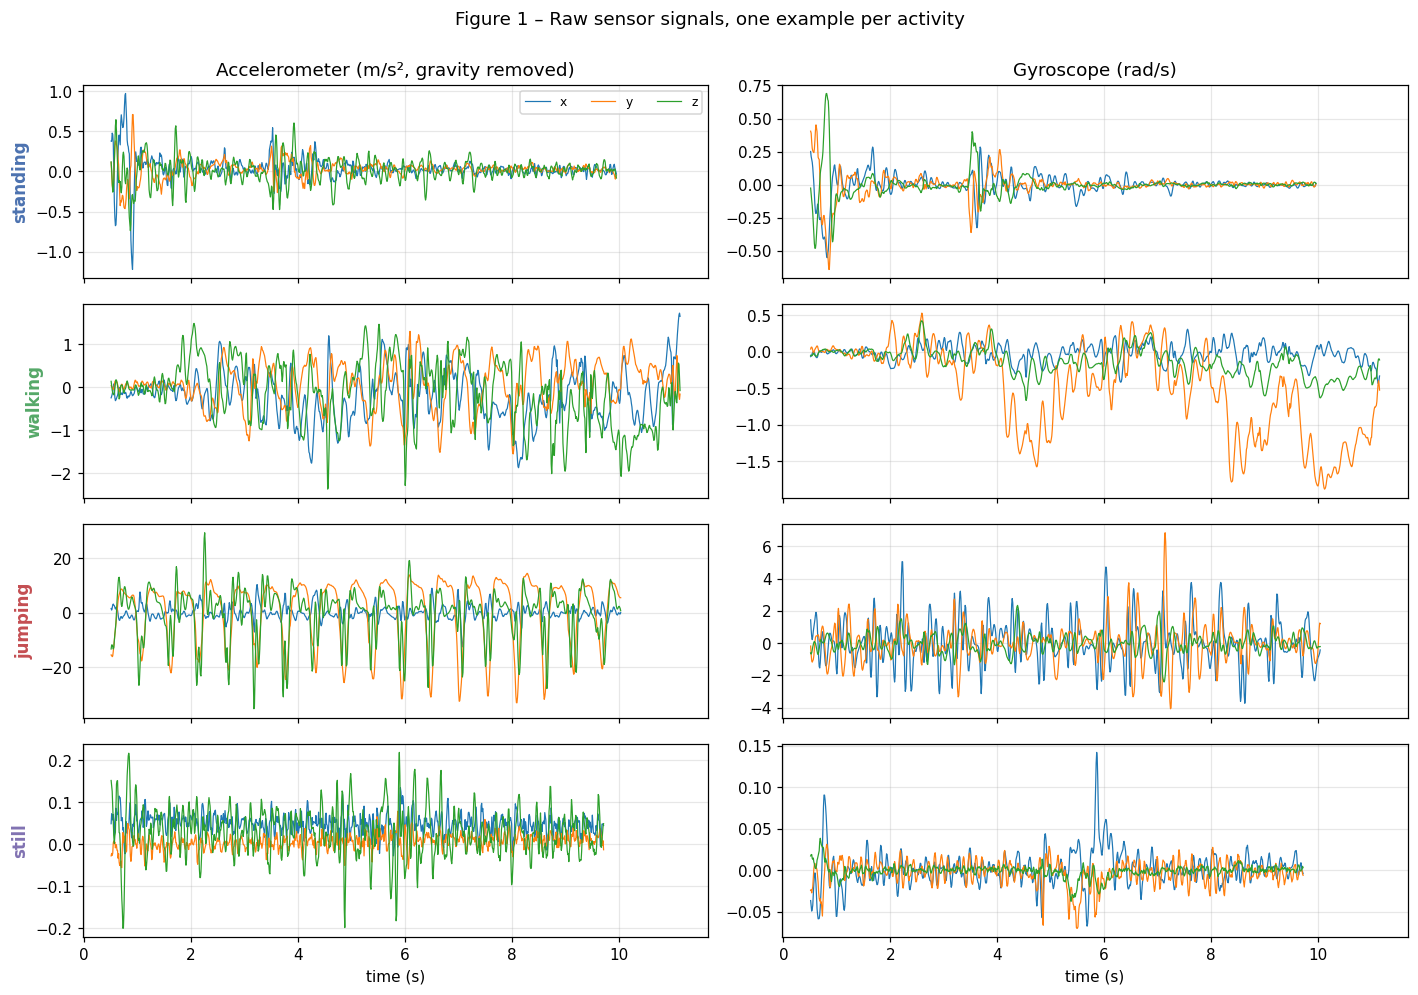

In [4]:
colors = {'standing': '#4C72B0', 'walking': '#55A868', 'jumping': '#C44E52', 'still': '#8172B2'}
fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for i, act in enumerate(STATES):
    df = train_recs[f'{act}01']
    for ax in 'xyz':
        axes[i, 0].plot(df.seconds, df[f'acc_{ax}'], lw=0.8, label=ax)
        axes[i, 1].plot(df.seconds, df[f'gyro_{ax}'], lw=0.8, label=ax)
    axes[i, 0].set_ylabel(act, fontsize=11, color=colors[act], fontweight='bold')
axes[0, 0].set_title('Accelerometer (m/s², gravity removed)')
axes[0, 1].set_title('Gyroscope (rad/s)')
axes[0, 0].legend(loc='upper right', ncol=3, fontsize=8)
for a in axes[-1]: a.set_xlabel('time (s)')
plt.suptitle('Figure 1 – Raw sensor signals, one example per activity', y=1.0)
plt.tight_layout(); plt.savefig('figures/fig1_raw_signals.png', bbox_inches='tight'); plt.show()

# 1.3 Phone orientation (gravity) per file
The gravity vector shows how the phone was held. This plot is important for the analysis: standing and still barely move, so the only obvious difference between them is the angle of the phone  and that angle was not the same in the test files as in the training files.

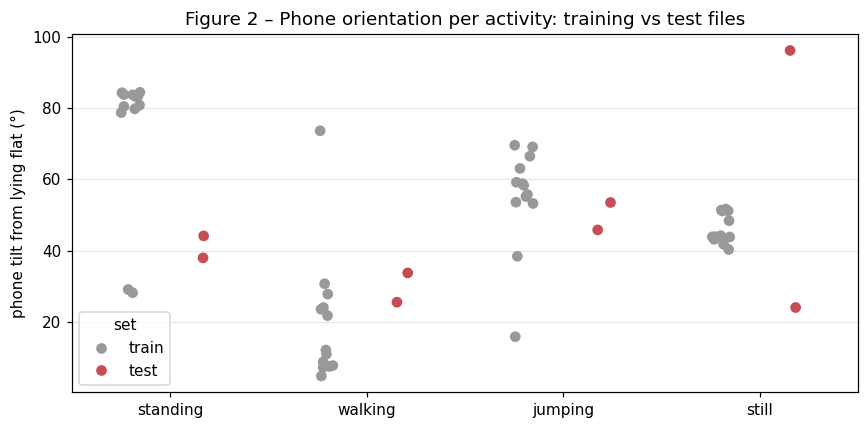

In [5]:
rows = []
for key, df in {**train_recs, **test_recs}.items():
    for lab, part in df.groupby('label'):
        g = part[['grav_x', 'grav_y', 'grav_z']].mean()
        tilt = np.degrees(np.arccos(np.clip(-g.grav_z / np.linalg.norm(g), -1, 1)))
        rows.append({'file': key, 'label': lab, 'set': 'test' if key.startswith('test') else 'train',
                     'tilt_from_flat_deg': tilt})
orient = pd.DataFrame(rows)
plt.figure(figsize=(8, 4))
sns.stripplot(data=orient, x='label', y='tilt_from_flat_deg', hue='set', order=STATES,
              dodge=True, size=7, palette={'train': '#999999', 'test': '#C44E52'})
plt.ylabel('phone tilt from lying flat (°)'); plt.xlabel('')
plt.title('Figure 2 – Phone orientation per activity: training vs test files')
plt.tight_layout(); plt.savefig('figures/fig2_orientation.png', bbox_inches='tight'); plt.show()

# 2. Windowing
The continuous signal was split into windows of 2 seconds (200 samples at 100Hz). The windows had 50% overlap which means 1 s = 100 samples.

2 second window

A human will walk or jump at approximately 1.5-3.5Hz. This means there are always a few full cycles inside each window, allowing us to get an idea of the rhythm.
The frequency resolution is good enough (200 samples at 100Hz gives an FFT frequency resolution of FS/N = 0.5 Hz) to tell the difference between walking and jumping rhythms.
It is still a short time period compared to how long an activity lasts (~10s), which means we get roughly 9 observations for each activity, giving us a good idea of where transitions have occurred.
Having 50% overlap means that we double the amount of observations.
Each window is an observation for the HMM. The test window was labelled based on what label it had the most samples of.

In [6]:
WIN, STEP = 2 * FS, 1 * FS     # 200 samples, 100-sample step
print(f'Window = {WIN} samples = {WIN/FS:.1f} s | step = {STEP/FS:.1f} s | FFT resolution = {FS/WIN:.2f} Hz')

Window = 200 samples = 2.0 s | step = 1.0 s | FFT resolution = 0.50 Hz


# 3. Feature Extraction (Time & Frequency Domain)

The features we extracted are based on the magnitude of each sensor (|a| = sqrt(x^2 + y^2 + z^2) and | ω| = sqrt(x^2 + y^2 + z^2)). This is unaffected by rotation of the phone.

| Num | Feature Name | Domain | Why it helps distinguish activities |
|-----|--------------|--------|-------------------------------------|
| 1 | acc_mag_std | Time | Measures the intensity of movement. High when jumping, medium when walking and near zero when standing/still. |
| 2 | gyro_mag_mean | Time | The phone will swing when walking or jumping. When standing, there will be minor body movements but if the phone is on a table there will be no movement. This is the key indicator for standing or still. |
| 3 | gyro_mag_std | Time | Measures the unevenness of rotation. More rhythmic movement will have a low standard deviation, such as walking or jumping. Still will have a consistent rotation. |
| 4 | acc_dom_freq | Frequency | Measures the rhythm of the activity. Walking will have a dominant frequency between 1.5-2Hz whilst jumping will be quicker. Standing/still will not have any distinct peak (just noise). |
| 5 | acc_spec_energy | Frequency | Measures the overall amount of energy throughout all frequencies. High energy when jumping. |
| 6 | gyro_spec_energy | Frequency | As above but for rotation. Provides more evidence for low/no movement. |

A Hann window was applied before performing the FFT to reduce spectral leakage. The mean was also removed to prevent the 0Hz frequency dominating.

Features were not included intentionally such as the mean of the linear acceleration (and SMA), gravity/angle of orientation. These values were largely affected by the offset of the sensor and random orientation of the phone when little movement occurred. Figure 2 shows that the orientation changed between training and test data meaning this would cause the model to learn the orientation of the phone rather than the activity.

In [7]:
FEATURES = ['acc_mag_std', 'gyro_mag_mean', 'gyro_mag_std',
            'acc_dom_freq', 'acc_spec_energy', 'gyro_spec_energy']
freqs = np.fft.rfftfreq(WIN, 1 / FS)
hann = np.hanning(WIN)
search_band = (freqs >= 0.3) & (freqs <= 15)

def spectrum(signal):
    x = signal - signal.mean()
    return np.abs(np.fft.rfft(x * hann)) ** 2

def window_features(seg):
    acc_mag = np.linalg.norm(seg[['acc_x', 'acc_y', 'acc_z']].values, axis=1)
    gyr_mag = np.linalg.norm(seg[['gyro_x', 'gyro_y', 'gyro_z']].values, axis=1)
    acc_spec, gyr_spec = spectrum(acc_mag), spectrum(gyr_mag)
    return {
        'acc_mag_std':      acc_mag.std(),
        'gyro_mag_mean':    gyr_mag.mean(),
        'gyro_mag_std':     gyr_mag.std(),
        'acc_dom_freq':     freqs[search_band][np.argmax(acc_spec[search_band])],
        'acc_spec_energy':  acc_spec.sum() / WIN,
        'gyro_spec_energy': gyr_spec.sum() / WIN,
    }

def make_windows(df, name):
    rows = []
    for start in range(0, len(df) - WIN + 1, STEP):
        seg = df.iloc[start:start + WIN]
        f = window_features(seg)
        f.update(label=seg.label.mode()[0], t_start=seg.seconds.iloc[0], file=name)
        rows.append(f)
    return pd.DataFrame(rows)

train_windows = [make_windows(df, k) for k, df in sorted(train_recs.items())]
test_windows  = {k: make_windows(df, k) for k, df in sorted(test_recs.items())}
train_df = pd.concat(train_windows, ignore_index=True)
print('Training windows per activity:', train_df.label.value_counts().to_dict())
print('Test windows per file:', {k: len(v) for k, v in test_windows.items()})
train_df.groupby('label')[FEATURES].median().loc[STATES].round(4)

Training windows per activity: {'standing': 106, 'still': 104, 'jumping': 103, 'walking': 87}
Test windows per file: {'test1': 40, 'test2': 39}


,acc_mag_std,gyro_mag_mean,gyro_mag_std,acc_dom_freq,acc_spec_energy,gyro_spec_energy
label,,,,,,
standing,0.0267,0.0220,0.0115,4.25,0.0267,0.0049
walking,0.6527,0.8801,0.4120,1.50,14.6010,5.9601
jumping,6.3923,1.7144,0.9090,4.00,1480.2615,30.4884
still,0.0251,0.0112,0.0060,6.50,0.0212,0.0013


# 3.1 Normalisation
Intensities/Energies: Log transform all features (except acc_dom_freq). All have a large dynamic range (≈ 0.01 to jump by ≈ 1000) and are heavily skewed. This results in the features having approximately a normal distribution for each class, aligning with our HMM assumption that emissions follow a Gaussian.
Z-Score: Standardise all features by subtracting the mean and dividing by standard deviation. This ensures all features are on the same scale.
We calculate the mean and standard deviation using just training windows. This ensures we do not have any information leakage from the test data.

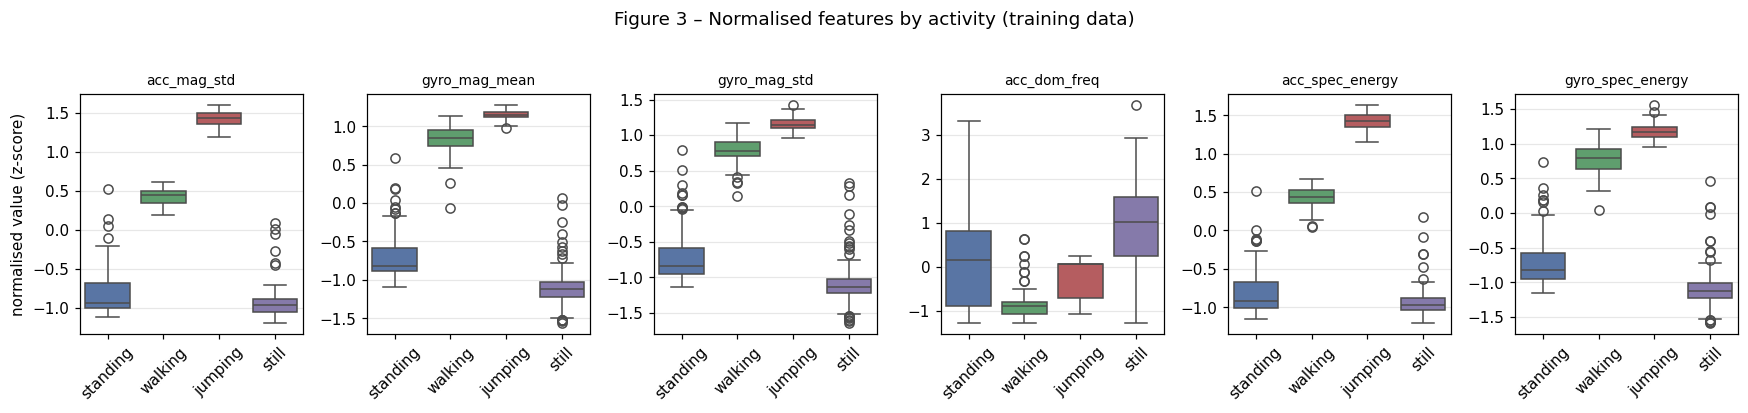

In [8]:
LOG_FEATURES = [f for f in FEATURES if f != 'acc_dom_freq']

def transform(df):
    X = df[FEATURES].copy()
    for c in LOG_FEATURES:
        X[c] = np.log(X[c] + 1e-6)
    return X.values

_raw = transform(train_df)
FEAT_MEAN, FEAT_STD = _raw.mean(0), _raw.std(0)
normalise = lambda df: (transform(df) - FEAT_MEAN) / FEAT_STD

X_train = normalise(train_df)
y_train = train_df.label.map(STATES.index).values
train_seqs = [normalise(w) for w in train_windows]

fig, axes = plt.subplots(1, len(FEATURES), figsize=(16, 3.6))
for j, f in enumerate(FEATURES):
    sns.boxplot(x=train_df.label, y=X_train[:, j], order=STATES, ax=axes[j],
                palette=colors, hue=train_df.label, legend=False)
    axes[j].set_title(f, fontsize=9); axes[j].set_xlabel(''); axes[j].tick_params(axis='x', rotation=45)
axes[0].set_ylabel('normalised value (z-score)')
plt.suptitle('Figure 3 – Normalised features by activity (training data)', y=1.03)
plt.tight_layout(); plt.savefig('figures/fig3_features.png', bbox_inches='tight'); plt.show()

## 4. Model Elements

Element Description in model.
Hidden states Z 4 activities: Stand, Walk, Jump, Still.
Observations X The 6D normalised feature vector for each 2 second window.
Transition probabilities A (4x4 matrix). The probability of moving from activity at window t to activity at window t+1. A = P(Z[t+1] = activity | Z[t] = activity).
Emission probabilities B. For each state a Gaussian distribution with diagonal covariance. B = P(X = x | state = k) = N(x; μ_k, diag(σ²_k)). As our features are continuous, Gaussian distributions are a better fit than discrete symbols.
Initial probabilities π. Probability that first window is activity k. π = P(Z[1] = activity k).

## 5. Algorithms and Why They Are Used

Baum-Welch (EM algorithm using forward backward). Used to train the model. Re-estimates initial state probabilities, transition probabilities and Gaussian mean/variance to maximise the likelihood of training sequences. Algorithm terminates when the training objective function (log likelihood + small prior used to smooth A and π) does not improve by more than ε = 10⁻⁴. This is a proper convergence check.
Viterbi. Used to decode the most likely sequence of activities. Uses transition probabilities to smooth out any single noisy windows. This increases sensitivity (less false negatives) and specificity (less false positives), increasing overall accuracy.
Forward. Calculates log likelihood.

All calculations are performed in log space (logsumexp) to prevent numerical underflow on long sequences.

In [9]:
class GaussianHMM:
    """Hidden Markov Model with diagonal-Gaussian emissions, implemented from scratch in NumPy."""

    def __init__(self, n_states, n_features, var_floor=1e-3):
        self.K, self.D, self.var_floor = n_states, n_features, var_floor
        self.pi = self.A = self.means = self.vars = None

    # emissions
    def log_emission(self, X):
        """log N(x_t | mu_k, diag(var_k)) for every window t and state k -> shape (T, K)."""
        diff = X[:, None, :] - self.means[None]
        return -0.5 * (np.sum(np.log(2 * np.pi * self.vars), axis=1)[None]
                       + np.sum(diff ** 2 / self.vars[None], axis=2))

    #  forward / backward
    def forward(self, logB):
        """Forward algorithm in log space. Returns log-alpha (T, K) and the sequence log-likelihood."""
        T, logA = len(logB), np.log(self.A)
        log_alpha = np.zeros((T, self.K))
        log_alpha[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + logA, axis=0) + logB[t]
        return log_alpha, logsumexp(log_alpha[-1])

    def backward(self, logB):
        """Backward algorithm in log space. Returns log-beta (T, K)."""
        T, logA = len(logB), np.log(self.A)
        log_beta = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(logA + (logB[t + 1] + log_beta[t + 1])[None], axis=1)
        return log_beta

    def log_likelihood(self, sequences):
        return sum(self.forward(self.log_emission(X))[1] for X in sequences)

    #  decoding
    def viterbi(self, X):
        """Most likely hidden-state path for one observation sequence."""
        logB, logA, T = self.log_emission(X), np.log(self.A), len(X)
        delta = np.zeros((T, self.K)); backptr = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            backptr[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.zeros(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = backptr[t + 1, path[t + 1]]
        return path

    #  training
    def baum_welch(self, sequences, tol=1e-4, max_iter=200, pseudocount=1.0, verbose=True):
        """EM over several sequences. Stops when the objective improves by less than tol."""
        history = []
        for it in range(max_iter):
            logA = np.log(self.A)
            pi_acc, gamma_acc = np.zeros(self.K), np.zeros(self.K)
            xi_acc, mean_acc = np.zeros((self.K, self.K)), np.zeros((self.K, self.D))
            sq_acc, total_ll = np.zeros((self.K, self.D)), 0.0
            for X in sequences:
                logB = self.log_emission(X)
                log_alpha, ll = self.forward(logB)
                log_beta = self.backward(logB)
                gamma = np.exp(log_alpha + log_beta - ll)
                if len(X) > 1:
                    log_xi = (log_alpha[:-1, :, None] + logA[None]
                              + (logB[1:] + log_beta[1:])[:, None, :] - ll)
                    xi_acc += np.exp(log_xi).sum(axis=0)
                pi_acc += gamma[0]; gamma_acc += gamma.sum(axis=0)
                mean_acc += gamma.T @ X; sq_acc += gamma.T @ (X ** 2)
                total_ll += ll

            objective = total_ll + pseudocount * np.log(self.A).sum() + np.log(self.pi).sum()
            history.append(objective)
            if verbose:
                print(f'iteration {it:3d}   log-likelihood = {total_ll:10.4f}   objective = {objective:10.4f}')
            if it > 0 and abs(history[-1] - history[-2]) < tol:
                if verbose: print(f'Converged: change < {tol} after {it} iterations')
                break
            # M-step (pseudocounts keep every transition possible, avoiding log(0))
            self.pi = (pi_acc + 1) / (pi_acc.sum() + self.K)
            self.A = (xi_acc + pseudocount) / (xi_acc + pseudocount).sum(axis=1, keepdims=True)
            self.means = mean_acc / gamma_acc[:, None]
            self.vars = np.maximum(sq_acc / gamma_acc[:, None] - self.means ** 2, self.var_floor)
        return history

### 5.1 Parameter Initialisation

We know the labels of the training windows, so we can start the model with some reasonable initial parameters (we also know which activity each hidden state represents):

B: The average and variance for each feature in each activity.

π: Uniform distribution (any first activity.)

A: Diagonal entries are 0.9, others are 0.1/3. This implies that activities last about 10 s ≈ 10 windows, which gives a roughly 1 − 1/10 = 0.9 probability of remaining in the same activity.

In [10]:
K, D = len(STATES), len(FEATURES)
hmm = GaussianHMM(K, D)
hmm.means = np.array([X_train[y_train == k].mean(0) for k in range(K)])
hmm.vars  = np.array([X_train[y_train == k].var(0) + 1e-3 for k in range(K)])
hmm.pi    = np.full(K, 1 / K)
hmm.A     = np.full((K, K), 0.1 / (K - 1)); np.fill_diagonal(hmm.A, 0.9)

import copy
hmm_init = copy.deepcopy(hmm)
print('Initial log-likelihood of training data:', round(hmm.log_likelihood(train_seqs), 2))

Initial log-likelihood of training data: 144.51


# 5.2 Train with Baum–Welch

iteration   0   log-likelihood =   144.5102   objective =    97.7293
iteration   1   log-likelihood =   446.7436   objective =   391.7881
iteration   2   log-likelihood =   483.2333   objective =   429.3041
iteration   3   log-likelihood =   495.4809   objective =   441.3521
iteration   4   log-likelihood =   498.0298   objective =   443.7442
iteration   5   log-likelihood =   498.2426   objective =   443.8904
iteration   6   log-likelihood =   498.2676   objective =   443.9021
iteration   7   log-likelihood =   498.2702   objective =   443.9037
iteration   8   log-likelihood =   498.2698   objective =   443.9040
iteration   9   log-likelihood =   498.2694   objective =   443.9040
Converged: change < 0.0001 after 9 iterations


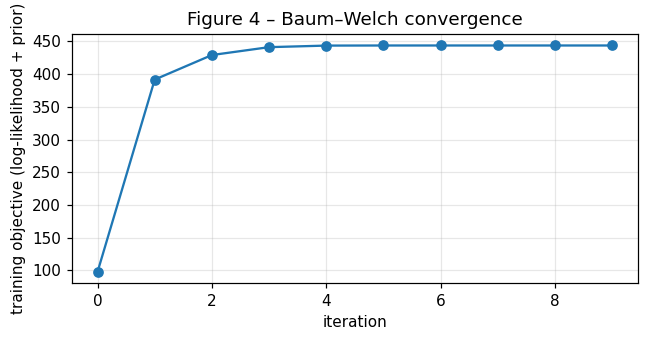

In [11]:
history = hmm.baum_welch(train_seqs, tol=1e-4, max_iter=200)

plt.figure(figsize=(6, 3.2))
plt.plot(history, marker='o')
plt.xlabel('iteration'); plt.ylabel('training objective (log-likelihood + prior)')
plt.title('Figure 4 – Baum–Welch convergence')
plt.tight_layout(); plt.savefig('figures/fig4_convergence.png', bbox_inches='tight'); plt.show()

### 5.3 Learned parameters: transition and emission probabilities

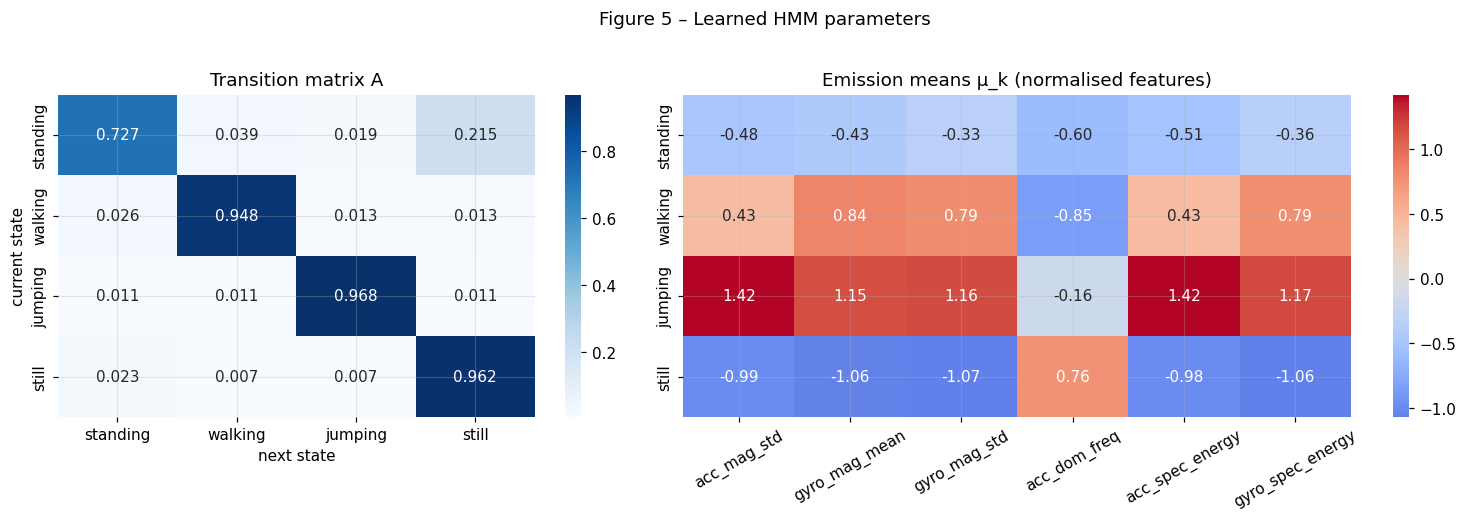

Initial state probabilities π: {'standing': 0.213, 'walking': 0.25, 'jumping': 0.25, 'still': 0.287}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.4]})
sns.heatmap(hmm.A, annot=True, fmt='.3f', cmap='Blues', xticklabels=STATES, yticklabels=STATES, ax=axes[0])
axes[0].set_xlabel('next state'); axes[0].set_ylabel('current state')
axes[0].set_title('Transition matrix A')
sns.heatmap(hmm.means, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=FEATURES, yticklabels=STATES, ax=axes[1])
axes[1].set_title('Emission means μ_k (normalised features)')
axes[1].tick_params(axis='x', rotation=30)
plt.suptitle('Figure 5 – Learned HMM parameters', y=1.02)
plt.tight_layout(); plt.savefig('figures/fig5_transition_emission.png', bbox_inches='tight'); plt.show()
print('Initial state probabilities π:', {s: round(float(p), 3) for s, p in zip(STATES, hmm.pi)})

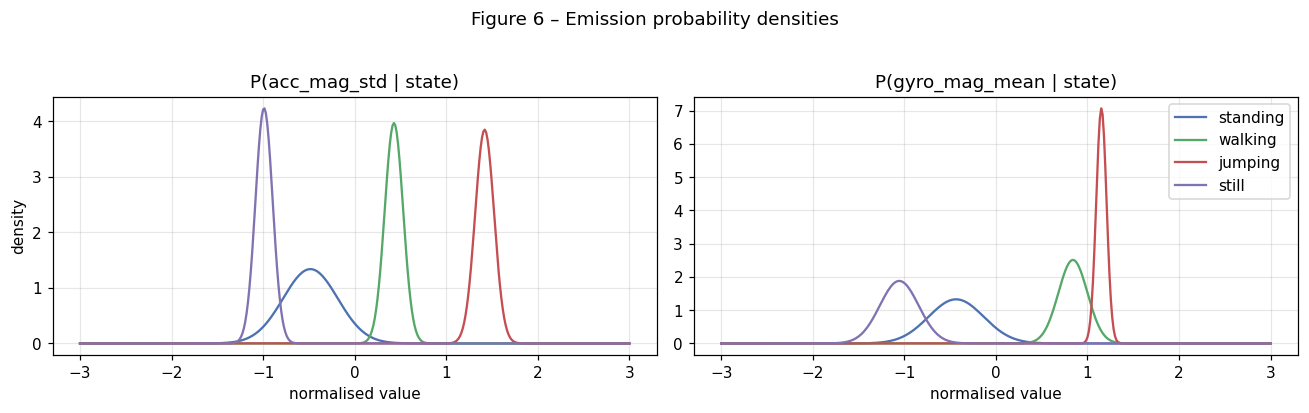

In [13]:
from scipy.stats import norm
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
grid = np.linspace(-3, 3, 400)
for ax, f in zip(axes, ['acc_mag_std', 'gyro_mag_mean']):
    j = FEATURES.index(f)
    for k, s in enumerate(STATES):
        ax.plot(grid, norm.pdf(grid, hmm.means[k, j], np.sqrt(hmm.vars[k, j])), label=s, color=colors[s])
    ax.set_title(f'P({f} | state)'); ax.set_xlabel('normalised value')
axes[0].set_ylabel('density'); axes[1].legend()
plt.suptitle('Figure 6 – Emission probability densities', y=1.03)
plt.tight_layout(); plt.savefig('figures/fig6_emission_densities.png', bbox_inches='tight'); plt.show()

## 6. Evaluation on unseen data

The test1 and test2 files were recorded in a separate session. All four activities were performed in quick succession but in a different order to that of the training data. The model needs to detect the activity changes. These files were never used in training or for calculating normalisation statistics. Viterbi decoding is applied to the full sequence of each file.

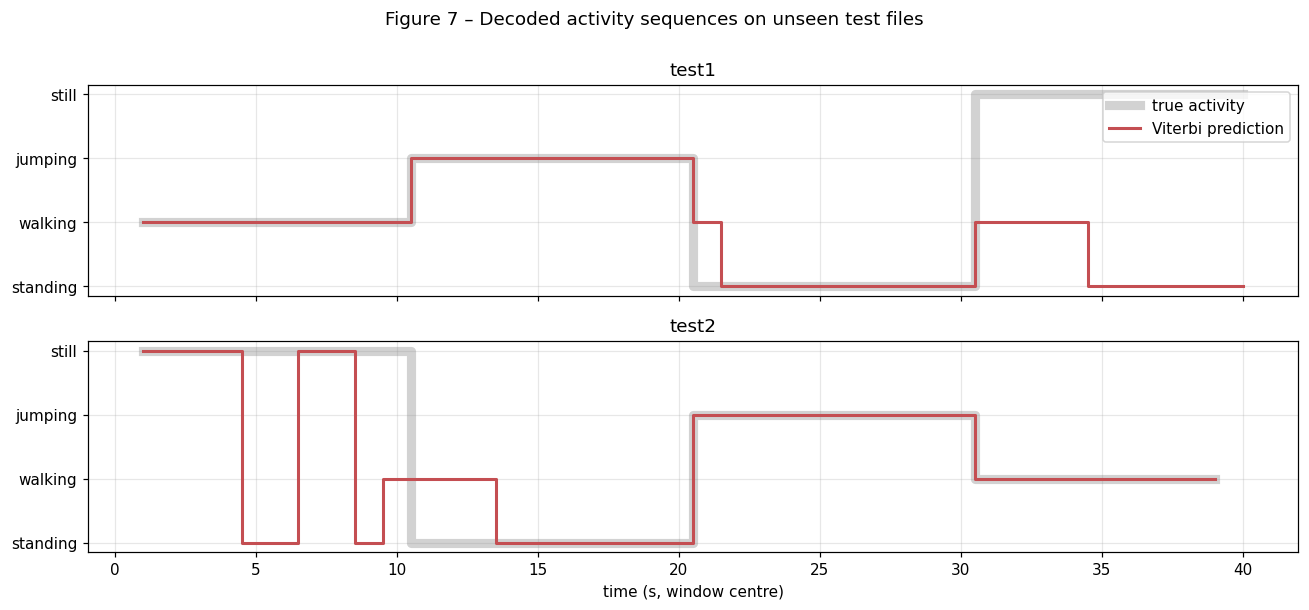

In [14]:
def decode_all(model):
    y_true, y_pred, per_file = [], [], {}
    for name, w in test_windows.items():
        pred = model.viterbi(normalise(w))
        true = w.label.map(STATES.index).values
        per_file[name] = (w.t_start.values, true, pred)
        y_true.append(true); y_pred.append(pred)
    return np.concatenate(y_true), np.concatenate(y_pred), per_file

y_true, y_pred, per_file = decode_all(hmm)

fig, axes = plt.subplots(len(per_file), 1, figsize=(12, 5.5), sharex=True)
for ax, (name, (t, true, pred)) in zip(axes, per_file.items()):
    t_mid = t + WIN / FS / 2
    ax.step(t_mid, true, where='mid', lw=6, alpha=0.35, color='grey', label='true activity')
    ax.step(t_mid, pred, where='mid', lw=2, color='#C44E52', label='Viterbi prediction')
    ax.set_yticks(range(K)); ax.set_yticklabels(STATES); ax.set_title(name)
axes[0].legend(loc='upper right'); axes[-1].set_xlabel('time (s, window centre)')
plt.suptitle('Figure 7 – Decoded activity sequences on unseen test files', y=1.0)
plt.tight_layout(); plt.savefig('figures/fig7_decoded_sequences.png', bbox_inches='tight'); plt.show()

### 6.1 Sensitivity, specificity and accuracy
For each activity (one-vs-rest): **sensitivity** = TP/(TP+FN), **specificity** = TN/(TN+FP), **accuracy** = (TP+TN)/N. Overall accuracy = correctly labelled windows / all windows.

In [15]:
def metrics_table(y_true, y_pred):
    rows = []
    for k, s in enumerate(STATES):
        tp = np.sum((y_true == k) & (y_pred == k)); fn = np.sum((y_true == k) & (y_pred != k))
        tn = np.sum((y_true != k) & (y_pred != k)); fp = np.sum((y_true != k) & (y_pred == k))
        rows.append({'State (Activity)': s, 'Number of Samples': int(tp + fn),
                     'Sensitivity': tp / (tp + fn) if tp + fn else np.nan,
                     'Specificity': tn / (tn + fp) if tn + fp else np.nan,
                     'Accuracy (one-vs-rest)': (tp + tn) / len(y_true)})
    t = pd.DataFrame(rows)
    t['Overall Accuracy'] = np.mean(y_true == y_pred)
    return t.round(3)

results = metrics_table(y_true, y_pred)
results.to_csv('figures/results_table.csv', index=False)
results

,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest),Overall Accuracy
0,standing,20,0.8,0.847,0.835,0.772
1,walking,19,1.0,0.850,0.886,0.772
2,jumping,20,1.0,1.000,1.000,0.772
3,still,20,0.3,1.000,0.823,0.772


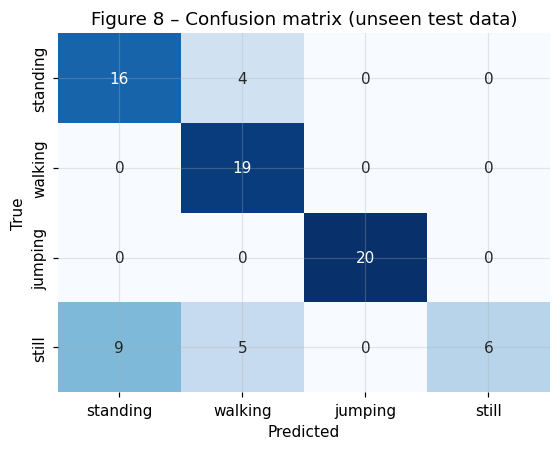

In [16]:
cm = pd.crosstab(pd.Series([STATES[i] for i in y_true], name='True'),
                 pd.Series([STATES[i] for i in y_pred], name='Predicted')).reindex(index=STATES, columns=STATES, fill_value=0)
plt.figure(figsize=(5.2, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Figure 8 – Confusion matrix (unseen test data)')
plt.tight_layout(); plt.savefig('figures/fig8_confusion_matrix.png', bbox_inches='tight'); plt.show()

### 6.2 Effect of Baum–Welch training and of the transition model
Comparison of (a) classifying each window independently with the emission model only, (b) Viterbi with the initial parameters, (c) Viterbi after Baum–Welch.

In [17]:
def window_only(model):
    preds = [model.log_emission(normalise(w)).argmax(1) for w in test_windows.values()]
    return np.concatenate(preds)

comparison = pd.DataFrame({
    'Model': ['Emissions only (no transitions)', 'Viterbi – initial parameters', 'Viterbi – after Baum–Welch'],
    'Overall accuracy': [np.mean(window_only(hmm) == y_true),
                         np.mean(decode_all(hmm_init)[1] == y_true),
                         np.mean(y_pred == y_true)]}).round(3)
comparison

,Model,Overall accuracy
0,Emissions only (no transitions),0.797
1,Viterbi – initial parameters,0.759
2,Viterbi – after Baum–Welch,0.772


# 7. Notes on analysis:

Easiest: Jumping and walking had very distinct intensity and rhythm properties compared to the rest (Figure 3, Figure 6).
Hardest: Standing and still are both very passive. The only reliable hint is the slight sway of the phone in the hand (gyro_mag_mean). Orientation should have helped separate these however the test files had different tilts (Figure 2) thus orientation was not used.
Transition errors: Sliding window that covers a transition (such as picking up/putting down the phone) will cause the activity to be mixed and often looks like walking.
Transition matrix: Training files only had one activity so Baum-Welch found very high self transitions (realistic as people perform activities for some time), and low switches. High transitions between standing and still show how uncertain the model is between these states.
Improvements: More people/phones, training sequences with actual transitions, same grip on phone, separate magnetometer/barometer, or Gaussian mixture emissions for each state.

## 8. Download outputs
Downloads `data/` (cleaned labelled CSVs) and `figures/` as one zip for the GitHub repo and the report.

In [18]:
os.makedirs('hmm_outputs', exist_ok=True)
for folder in ['data', 'figures']:
    shutil.copytree(folder, f'hmm_outputs/{folder}', dirs_exist_ok=True)
shutil.make_archive('hmm_outputs', 'zip', 'hmm_outputs')
try:
    from google.colab import files
    files.download('hmm_outputs.zip')
except ImportError:
    print('Saved hmm_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>